# Deliverable 1

### Task 1: 
Sources used
    - https://frost.met.no/python_example.html and week 5 lecture

In [289]:
import pandas as pd
import requests
import matplotlib.pyplot as plt

In [ ]:
client_id = open("../frost_id/client_id.txt").read()

# Dates to get data from
dates = {
    1925: "1925-01-01/1925-12-31",
    2025: "2025-01-01/2025-12-31"
}

# A dictionary to store data by year(dates)
frost_payloads = {}

endpoint = "https://frost.met.no/observations/v0.jsonld"

# Looping through the dates dict to reduce code replication for task 3
for year, reference_time in dates.items():
    
    # Week 5 lecture have been used for the code inside this loop
    parameters = {
        "sources": "SN17850",
        "elements": "mean(air_temperature P1D)",
        "referencetime": reference_time
    }

    r = requests.get(endpoint, parameters, auth=(client_id, ""))

    assert r.status_code == 200
    frost_payloads[year] = r.json()

data_1925 = frost_payloads[1925]["data"]
data_2025 = frost_payloads[2025]["data"]

In [291]:
# Converts list into dataframe and sets the time as index
# Again doing it with a loop to handle both 2025 and 1925 in same code block
# Week 5 lecture have been used for the code inside the loop 

temperature_data = {}

for year, payload in frost_payloads.items():
    temp_data = [
        {
            "Time": pd.to_datetime(entry["referenceTime"]),
            "T_avg": entry["observations"][0]["value"]
        }
        for entry in payload["data"]
        ]
    
    temperature_data[year] = (pd.DataFrame(temp_data).set_index("Time"))

df_1925 = temperature_data[1925]
df_2025 = temperature_data[2025]

##### Plotting of mean air temperature

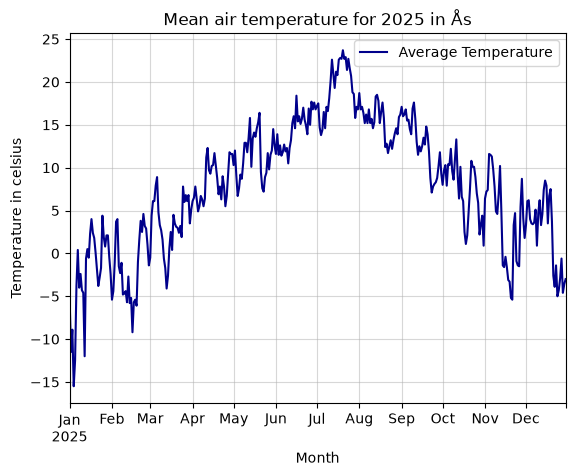

In [292]:
df_2025.plot(
    y="T_avg",
    kind="line",
    color="darkblue",
    label="Average Temperature",
    title=("Mean air temperature for 2025 in Ås"),
    xlabel=("Month"),
    ylabel=("Temperature in celsius"),
    )

plt.grid(alpha=0.5)

plt.minorticks_off() # Only showing monthly ticks
plt.show()

##### Discussion of plot:
For the first plot we've decided to use a line plot, simply because it is the most informative when looking at time series data of temperature.
A dark blue color have been chosen for high contrast. By using .minorticks_off() we've removed ticks that was difficult to see what was pointing to, only leaving us with ticks for each month. Otherwise, labels and titles have been named to give information about what the plot is about.

From the plot we can see that the highest average temperatures are in july and the coldes month january/february.



Summary table of temperature

In [293]:
summary_table_2025 = pd.DataFrame({
    "mean": df_2025.mean(),
    "median": df_2025.median(),
    "min": df_2025.min(),
    "max": df_2025.max()
    }).round(1)

# Rename T_avg
summary_table_2025.index = ["Temperature (°C)"]

print(f"Average temperatures in Ås, 2025\n {'_' * 50}")
print(summary_table_2025)

Average temperatures in Ås, 2025
 __________________________________________________
                  mean  median   min   max
Temperature (°C)   7.9     8.4 -15.5  23.7


##### Discussion of summary table:
Here we've made a data frame for the summary table, then found statistics by using corresponding statistic methods. We've decided using round to get all the statistics neat and similiar in decimals. 
From the statistics we get the yearly mean of 7.9 celsius and median of 8.4, meaning we might have an asymetrical distribution.

### Task 2

### Task 3

##### Plot of mean temperatures in 1925 and 2025
The 1925 temperatures have been retrieved earlier in the code (inside the loops in task 1).
This was done to reduce code duplication, therefore only plot and summary table will be shown in this section. 

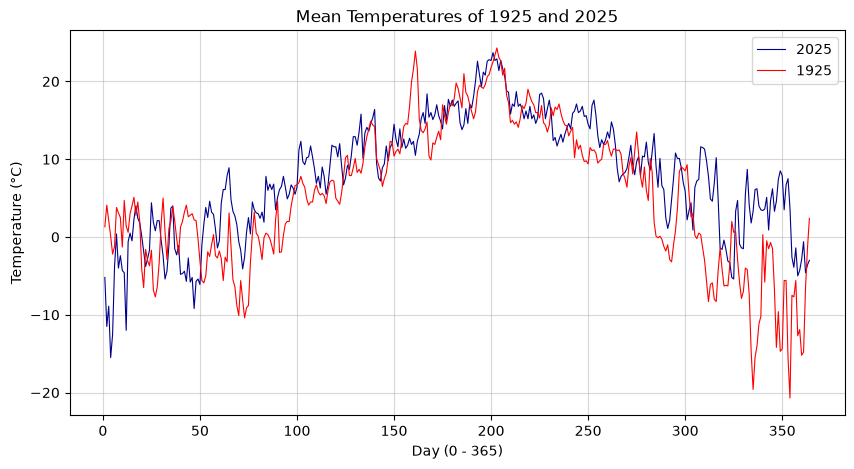

In [294]:
# Start by stretching the plot a bit so it is easier to read
plt.figure(figsize=(10, 5))

# 2025 data
plt.plot(df_2025.index.dayofyear, df_2025, color="darkblue", linewidth="0.8", label="2025")
# 1925 data
plt.plot(df_1925.index.dayofyear, df_1925, color="red", linewidth="0.8", label="1925")

plt.xlabel("Day (0 - 365)")
plt.ylabel("Temperature (°C)")
plt.title("Mean Temperatures of 1925 and 2025")

plt.legend()
plt.grid(alpha=0.5)

plt.show()

In the plot we use the index to get the x-axis then use .dayofyear to get days for better comparision (without we would get all 1925 data mashed to the left of the plot and 2025 data mashed to the right of the plot).

##### Summary Table for 1925 and 2025

In [295]:
combined = pd.concat(
    [
        df_1925["T_avg"].rename("1925"),
        df_2025["T_avg"].rename("2025")
    ],
    axis=1
)

summary_combined = pd.DataFrame({
    "mean": combined.mean(),
    "median": combined.median(),
    "min": combined.min(),
    "max": combined.max()
    }).round(1)

# naming the column as year
summary_combined.index.name = "Year"

print(f"Average temperatures in Ås 1925 and 2025\n {'_' * 50}")
print(summary_combined)

Average temperatures in Ås 1925 and 2025
 __________________________________________________
      mean  median   min   max
Year                          
1925   5.3     5.3 -20.7  24.3
2025   7.9     8.4 -15.5  23.7


##### Discussion of summary
For this summary table we've used .concat to combine the dataframes of 1925 and 2025. Without renaming the T_avg we get some weird outputs, hence the .rename. Otherwise the statistics coding is the same as in task 1, other then the new dataframe. For naming the columns we had to use .index.name instead of just .index for it to work. Again, the printout is the same as task 1. 

##### Some description of the statistics :)
The statistics shows us a bigger range in the 1925 temperatures than 2025. But the important difference will be to look at the mean and median. We can see that the mean and median in 1925 is the same, meaning the temperatures are symmetrical distributed (also colder in 1925 than 2025). Since the mean and median in 2025 don't match up it tells us that the statistics are might be skewed but we can not conclude anything based only on this. The main point, it is hotter on average in 2025 than in 1925. 

### Task 4

### Task 5

In [ ]:
def moving_average(dataframe: pd.DataFrame, column: str="T_avg", time_window: int=7):
    """
    Calculates 7-day moving average for temperature.
        Example: first calculate day 1-7, then 2-8 and so on.
    
    args:
        dataframe: a pandas dataframe of average air temperatures.
        column: name of temperature column, default: T_avg
        time_window: Number of days for moving temp, default: 7
    """
    return dataframe[column].rolling(window=time_window).mean()

moving_average(df_2025)


Time
2025-01-01 00:00:00+00:00         NaN
2025-01-02 00:00:00+00:00         NaN
2025-01-03 00:00:00+00:00         NaN
2025-01-04 00:00:00+00:00         NaN
2025-01-05 00:00:00+00:00         NaN
                               ...   
2025-12-26 00:00:00+00:00   -2.342857
2025-12-27 00:00:00+00:00   -2.957143
2025-12-28 00:00:00+00:00   -3.242857
2025-12-29 00:00:00+00:00   -3.200000
2025-12-30 00:00:00+00:00   -3.428571
Name: T_avg, Length: 364, dtype: float64